In [1]:

# ==================================================
# CELL 1 - IMPORT LIBRARY DAN KONFIGURASI
# Outcome 3: Motor Load Classification
# Metode: Random Forest + Harmonic Features
# ==================================================

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.signal import welch

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

import joblib

# Direktori proyek
BASE_DIR = Path.cwd()
OUTPUT_DIR = BASE_DIR / "outputs"
MODEL_DIR = OUTPUT_DIR / "models"

MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Konfigurasi sinyal
FS = 12000
WINDOW_SIZE = 12000
RANDOM_STATE = 42

# Rentang frekuensi harmonik
FREQUENCY_BANDS = {
    "fundamental": (25, 35),
    "harmonic_2": (50, 65),
    "harmonic_3": (80, 95)
}

print("Konfigurasi berhasil!")
print("Direktori proyek:", BASE_DIR)
print("Sampling rate:", FS, "Hz")
print("Window size:", WINDOW_SIZE, "sampel")
print("Durasi segmen:", WINDOW_SIZE / FS, "detik")


Konfigurasi berhasil!
Direktori proyek: d:\python\sem 5\Pemrosesan sinyal\Tugas Besar
Sampling rate: 12000 Hz
Window size: 12000 sampel
Durasi segmen: 1.0 detik


In [2]:

# ==================================================
# CELL 2 - LOAD DATASET SINYAL
# ==================================================

DATA_PATH = OUTPUT_DIR / "bearing_clean.csv"

signal_df = pd.read_csv(
    DATA_PATH,
    usecols=[
        "source_file",
        "sample_index",
        "vibration",
        "motor_load_hp"
    ]
)

# Normalisasi nama file pada metadata
signal_df["source_file"] = (
    signal_df["source_file"]
    .astype(str)
    .str.strip()
    .str.replace(r"\s+\.mat$", ".mat", regex=True)
)

# Validasi data
assert signal_df["vibration"].notna().all()
assert signal_df["motor_load_hp"].notna().all()
assert signal_df["source_file"].nunique() == 40

print("DATASET BERHASIL DIMUAT")
print("=" * 40)
print("Jumlah sampel:", len(signal_df))
print("Jumlah rekaman:", signal_df["source_file"].nunique())

print("\nDistribusi Rekaman Berdasarkan Beban:")
display(
    signal_df[
        ["source_file", "motor_load_hp"]
    ]
    .drop_duplicates()
    ["motor_load_hp"]
    .value_counts()
    .sort_index()
)

print("\nContoh dataset:")
display(signal_df.head())


DATASET BERHASIL DIMUAT
Jumlah sampel: 4815787
Jumlah rekaman: 40

Distribusi Rekaman Berdasarkan Beban:


motor_load_hp
0    10
1    10
2    10
3    10
Name: count, dtype: int64


Contoh dataset:


,source_file,motor_load_hp,sample_index,vibration
0,97.mat,0,0,0.055947
1,97.mat,0,1,0.015231
2,97.mat,0,2,-0.079317
3,97.mat,0,3,0.045434
4,97.mat,0,4,0.047412


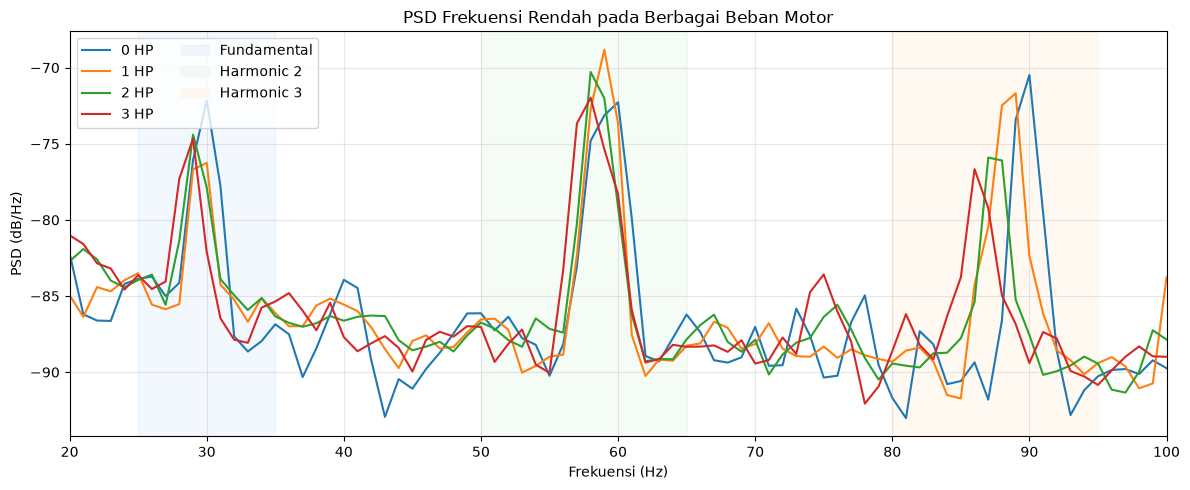

In [3]:

# ==================================================
# CELL 3 - VISUALISASI PSD DAN HARMONIK
# ==================================================

normal_files = {
    0: "97.mat",
    1: "98.mat",
    2: "99.mat",
    3: "100.mat"
}

fig, ax = plt.subplots(figsize=(12, 5))

for load, file_name in normal_files.items():

    subset = signal_df[
        signal_df["source_file"] == file_name
    ].sort_values("sample_index")

    signal = subset["vibration"].to_numpy()

    # Hilangkan komponen DC
    signal = signal - np.mean(signal)

    # Hitung Power Spectral Density
    frequencies, psd = welch(
        signal,
        fs=FS,
        nperseg=WINDOW_SIZE
    )

    # Fokus pada frekuensi 20-100 Hz
    mask = (
        (frequencies >= 20) &
        (frequencies <= 100)
    )

    ax.plot(
        frequencies[mask],
        10 * np.log10(psd[mask] + 1e-20),
        label=f"{load} HP",
        linewidth=1.5
    )

# Tandai rentang pencarian harmonik
colors = ["#DCEBFA", "#E5F4E3", "#FFF0D9"]

for (name, (low, high)), color in zip(
    FREQUENCY_BANDS.items(), colors
):
    ax.axvspan(
        low, high,
        color=color,
        alpha=0.35,
        label=name.replace("_", " ").title()
    )

ax.set_title(
    "PSD Frekuensi Rendah pada Berbagai Beban Motor"
)
ax.set_xlabel("Frekuensi (Hz)")
ax.set_ylabel("PSD (dB/Hz)")
ax.set_xlim(20, 100)
ax.grid(alpha=0.3)
ax.legend(ncol=2)

plt.tight_layout()
plt.show()


In [4]:

# ==================================================
# CELL 4 - EKSTRAKSI FITUR HARMONIK
# ==================================================

harmonic_features = []

for file_name, group in signal_df.groupby("source_file"):

    group = group.sort_values("sample_index")

    signal = group["vibration"].to_numpy()
    load = int(group["motor_load_hp"].iloc[0])

    n_segments = len(signal) // WINDOW_SIZE

    for segment_id in range(n_segments):

        start = segment_id * WINDOW_SIZE
        end = start + WINDOW_SIZE

        segment = signal[start:end]

        # Menghilangkan komponen DC
        segment = segment - np.mean(segment)

        # Menghitung PSD menggunakan Welch
        frequencies, psd = welch(
            segment,
            fs=FS,
            nperseg=WINDOW_SIZE
        )

        row = {
            "source_file": file_name,
            "segment_id": segment_id,
            "motor_load_hp": load
        }

        # Ekstraksi puncak pada setiap pita harmonik
        for name, (low, high) in FREQUENCY_BANDS.items():

            mask = (
                (frequencies >= low) &
                (frequencies <= high)
            )

            band_freq = frequencies[mask]
            band_psd = psd[mask]

            peak_idx = np.argmax(band_psd)

            row[f"{name}_frequency"] = (
                band_freq[peak_idx]
            )

            row[f"{name}_power"] = (
                band_psd[peak_idx]
            )

        harmonic_features.append(row)

# Membuat dataset fitur
df_harmonic = pd.DataFrame(harmonic_features)

# Menentukan kolom fitur
harmonic_feature_columns = [
    "fundamental_frequency",
    "fundamental_power",
    "harmonic_2_frequency",
    "harmonic_2_power",
    "harmonic_3_frequency",
    "harmonic_3_power"
]

# Validasi hasil
assert df_harmonic["source_file"].nunique() == 40

assert df_harmonic[
    harmonic_feature_columns
].notna().all().all()

print("HASIL EKSTRAKSI FITUR HARMONIK")
print("=" * 45)
print("Jumlah segmen:", len(df_harmonic))
print(
    "Jumlah rekaman:",
    df_harmonic["source_file"].nunique()
)
print(
    "Jumlah fitur:",
    len(harmonic_feature_columns)
)

display(df_harmonic.head())

# Simpan dataset fitur
FEATURE_PATH = (
    OUTPUT_DIR / "bearing_features_harmonic.csv"
)

df_harmonic.to_csv(
    FEATURE_PATH,
    index=False
)

print("\nDataset fitur berhasil disimpan:")
print(FEATURE_PATH)


HASIL EKSTRAKSI FITUR HARMONIK
Jumlah segmen: 395
Jumlah rekaman: 40
Jumlah fitur: 6


,source_file,segment_id,motor_load_hp,fundamental_frequency,fundamental_power,harmonic_2_frequency,harmonic_2_power,harmonic_3_frequency,harmonic_3_power
0,100.mat,0,3,29.0,3.157897e-08,59.0,6.068852e-08,86.0,2.151879e-08
1,100.mat,1,3,29.0,2.450639e-08,58.0,9.452766e-08,86.0,2.292923e-08
2,100.mat,2,3,29.0,1.745868e-08,58.0,5.820575e-08,86.0,3.285069e-08
3,100.mat,3,3,29.0,2.078117e-08,57.0,3.692090e-08,86.0,2.088012e-08
4,100.mat,4,3,29.0,3.649741e-08,58.0,5.403047e-08,86.0,3.318503e-08



Dataset fitur berhasil disimpan:
d:\python\sem 5\Pemrosesan sinyal\Tugas Besar\outputs\bearing_features_harmonic.csv


STATISTIK FREKUENSI HARMONIK


fundamental_frequency         harmonic_2_frequency          \
                               mean     std                 mean     std   
motor_load_hp                                                              
0                             30.00  0.0000                59.77  0.3498   
1                             29.89  0.0994                59.06  0.2011   
2                             29.00  0.0000                58.70  0.6055   
3                             28.95  0.1269                58.27  1.0012   

              harmonic_3_frequency          
                              mean     std  
motor_load_hp                               
0                            90.07  0.1636  
1                            88.96  0.0699  
2                            87.44  0.3864  
3                            85.97  0.3199

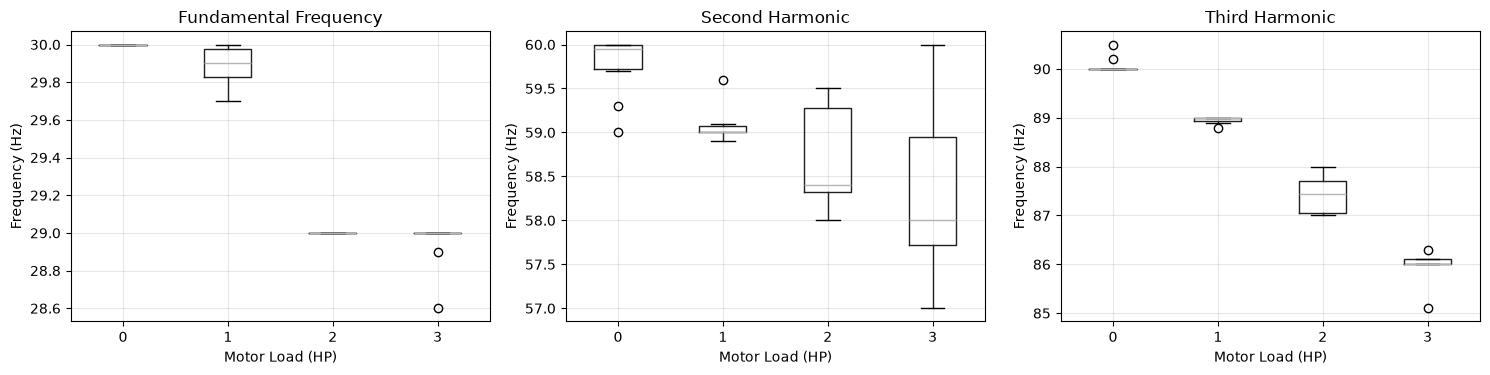

In [5]:

# ==================================================
# CELL 5 - ANALISIS DISTRIBUSI FITUR HARMONIK
# ==================================================

harmonic_frequency_columns = [
    "fundamental_frequency",
    "harmonic_2_frequency",
    "harmonic_3_frequency"
]

# Rata-rata fitur setiap rekaman
recording_harmonic = (
    df_harmonic
    .groupby(
        ["source_file", "motor_load_hp"],
        as_index=False
    )[harmonic_frequency_columns]
    .mean()
)

# Statistik berdasarkan beban motor
harmonic_summary = (
    recording_harmonic
    .groupby("motor_load_hp")[
        harmonic_frequency_columns
    ]
    .agg(["mean", "std"])
)

print("STATISTIK FREKUENSI HARMONIK")
display(harmonic_summary.round(4))

# Visualisasi distribusi
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

titles = [
    "Fundamental Frequency",
    "Second Harmonic",
    "Third Harmonic"
]

for ax, feature, title in zip(
    axes,
    harmonic_frequency_columns,
    titles
):
    recording_harmonic.boxplot(
        column=feature,
        by="motor_load_hp",
        ax=ax
    )

    ax.set_title(title)
    ax.set_xlabel("Motor Load (HP)")
    ax.set_ylabel("Frequency (Hz)")
    ax.grid(alpha=0.3)

plt.suptitle("")
plt.tight_layout()
plt.show()


In [6]:

# ==================================================
# CELL 6 - TRAIN TEST SPLIT BERDASARKAN REKAMAN
# ==================================================

# Metadata setiap rekaman
recording_info = (
    signal_df[
        ["source_file", "motor_load_hp"]
    ]
    .drop_duplicates()
    .reset_index(drop=True)
)

# Ambil informasi kondisi dan ukuran cacat
# dari dataset fitur utama
metadata_df = pd.read_csv(
    OUTPUT_DIR / "bearing_features.csv",
    usecols=[
        "source_file",
        "condition",
        "defect_size_inch"
    ]
)

metadata_df["source_file"] = (
    metadata_df["source_file"]
    .astype(str)
    .str.strip()
    .str.replace(r"\s+\.mat$", ".mat", regex=True)
)

metadata_df = metadata_df.drop_duplicates(
    subset=["source_file"]
)

recording_info = recording_info.merge(
    metadata_df,
    on="source_file",
    how="left",
    validate="one_to_one"
)

assert recording_info["condition"].notna().all()

# Kelompok konfigurasi bearing
recording_info["bearing_group"] = (
    recording_info["condition"].astype(str)
    + "_"
    + recording_info["defect_size_inch"].astype(str)
)

assert recording_info["bearing_group"].nunique() == 10

# Pemilihan rekaman testing
rng = np.random.default_rng(RANDOM_STATE)

remaining = {0: 3, 1: 3, 2: 2, 3: 2}
test_rows = []

group_names = rng.permutation(
    recording_info["bearing_group"].unique()
)

for group_name in group_names:

    candidates = recording_info[
        recording_info["bearing_group"] == group_name
    ]

    available_loads = [
        load
        for load, count in remaining.items()
        if count > 0
    ]

    eligible = candidates[
        candidates["motor_load_hp"].isin(
            available_loads
        )
    ]

    chosen = eligible.sample(
        n=1,
        random_state=int(
            rng.integers(0, 1000000)
        )
    )

    test_rows.append(chosen)

    selected_load = int(
        chosen["motor_load_hp"].iloc[0]
    )

    remaining[selected_load] -= 1

test_recordings = pd.concat(
    test_rows,
    ignore_index=True
)

test_files = test_recordings[
    "source_file"
].tolist()

train_files = recording_info.loc[
    ~recording_info["source_file"].isin(test_files),
    "source_file"
].tolist()

# Fitur dan target
X = df_harmonic[harmonic_feature_columns]
y = df_harmonic["motor_load_hp"].astype(int)
groups = df_harmonic["source_file"]

train_mask = groups.isin(train_files)
test_mask = groups.isin(test_files)

X_train = X.loc[train_mask]
X_test = X.loc[test_mask]

y_train = y.loc[train_mask]
y_test = y.loc[test_mask]

# Validasi
assert len(train_files) == 30
assert len(test_files) == 10
assert set(train_files).isdisjoint(test_files)
assert all(v == 0 for v in remaining.values())

print("HASIL PEMBAGIAN DATA")
print("=" * 40)

print("Rekaman Training :", len(train_files))
print("Rekaman Testing  :", len(test_files))
print("Segmen Training  :", len(X_train))
print("Segmen Testing   :", len(X_test))

print("\nDistribusi beban testing:")
display(
    test_recordings[
        "motor_load_hp"
    ].value_counts().sort_index()
)

print("\nDaftar rekaman testing:")
display(
    test_recordings.sort_values(
        ["condition", "defect_size_inch"]
    )
)


HASIL PEMBAGIAN DATA
Rekaman Training : 30
Rekaman Testing  : 10
Segmen Training  : 295
Segmen Testing   : 100

Distribusi beban testing:


motor_load_hp
0    3
1    3
2    2
3    2
Name: count, dtype: int64


Daftar rekaman testing:


,source_file,motor_load_hp,condition,defect_size_inch,bearing_group
5,119.mat,1,Ball Fault,0.007,Ball Fault_0.007
0,185.mat,0,Ball Fault,0.014,Ball Fault_0.014
9,223.mat,1,Ball Fault,0.021,Ball Fault_0.021
8,108.mat,3,Inner Race,0.007,Inner Race_0.007
6,170.mat,1,Inner Race,0.014,Inner Race_0.014
3,211.mat,2,Inner Race,0.021,Inner Race_0.021
2,99.mat,2,Normal,NaN,Normal_nan
4,130.mat,0,Outer Race,0.007,Outer Race_0.007
1,200.mat,3,Outer Race,0.014,Outer Race_0.014
7,234.mat,0,Outer Race,0.021,Outer Race_0.021


In [7]:

# ==================================================
# CELL 7 - TRAINING RANDOM FOREST
# ==================================================

model_rf_harmonic = RandomForestClassifier(
    n_estimators=300,
    max_depth=8,
    min_samples_split=5,
    min_samples_leaf=2,
    max_features="sqrt",
    class_weight="balanced",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

# Melatih model menggunakan data training
model_rf_harmonic.fit(X_train, y_train)

# Prediksi training dan testing
y_pred_train = model_rf_harmonic.predict(X_train)
y_pred_test = model_rf_harmonic.predict(X_test)

print("TRAINING RANDOM FOREST BERHASIL!")
print("=" * 40)
print("Jumlah fitur:", X_train.shape[1])
print("Jumlah segmen training:", len(X_train))
print("Jumlah segmen testing:", len(X_test))


TRAINING RANDOM FOREST BERHASIL!
Jumlah fitur: 6
Jumlah segmen training: 295
Jumlah segmen testing: 100


HASIL EVALUASI RANDOM FOREST


,Dataset,Accuracy,Macro Precision,Macro Recall,Macro F1
0,Training,0.9661,0.9711,0.9683,0.9682
1,Testing,0.9900,0.9881,0.9875,0.9875



CLASSIFICATION REPORT - TESTING
              precision    recall  f1-score   support

        0 HP       1.00      1.00      1.00        30
        1 HP       1.00      1.00      1.00        30
        2 HP       0.95      1.00      0.98        20
        3 HP       1.00      0.95      0.97        20

    accuracy                           0.99       100
   macro avg       0.99      0.99      0.99       100
weighted avg       0.99      0.99      0.99       100



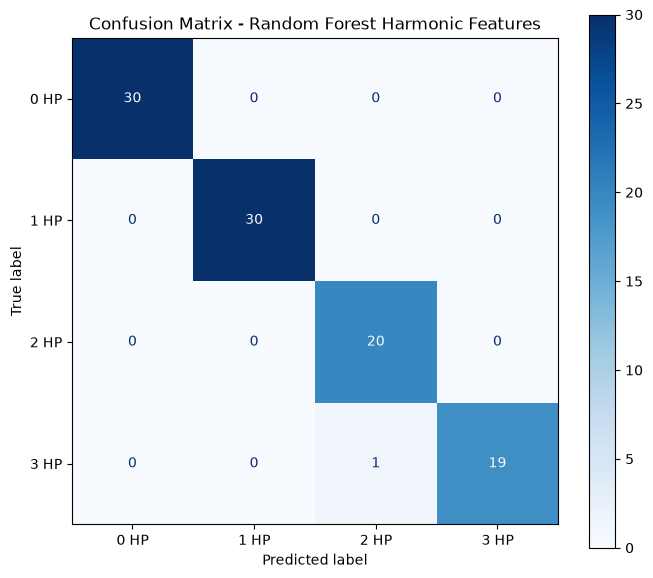

In [8]:

# ==================================================
# CELL 8 - EVALUASI RANDOM FOREST
# ==================================================

evaluation_results = pd.DataFrame({
    "Dataset": ["Training", "Testing"],
    "Accuracy": [
        accuracy_score(y_train, y_pred_train),
        accuracy_score(y_test, y_pred_test)
    ],
    "Macro Precision": [
        precision_score(
            y_train, y_pred_train,
            average="macro", zero_division=0
        ),
        precision_score(
            y_test, y_pred_test,
            average="macro", zero_division=0
        )
    ],
    "Macro Recall": [
        recall_score(
            y_train, y_pred_train,
            average="macro", zero_division=0
        ),
        recall_score(
            y_test, y_pred_test,
            average="macro", zero_division=0
        )
    ],
    "Macro F1": [
        f1_score(
            y_train, y_pred_train,
            average="macro", zero_division=0
        ),
        f1_score(
            y_test, y_pred_test,
            average="macro", zero_division=0
        )
    ]
})

print("HASIL EVALUASI RANDOM FOREST")
display(evaluation_results.round(4))

print("\nCLASSIFICATION REPORT - TESTING")
print(
    classification_report(
        y_test,
        y_pred_test,
        labels=[0, 1, 2, 3],
        target_names=["0 HP", "1 HP", "2 HP", "3 HP"],
        zero_division=0
    )
)

# Confusion Matrix
fig, ax = plt.subplots(figsize=(7, 6))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_test,
    labels=[0, 1, 2, 3],
    display_labels=["0 HP", "1 HP", "2 HP", "3 HP"],
    cmap="Blues",
    values_format="d",
    ax=ax
)

ax.set_title(
    "Confusion Matrix - Random Forest Harmonic Features"
)

plt.tight_layout()
plt.show()


HASIL EVALUASI TINGKAT REKAMAN


,source_file,actual,predicted,total_segments,correct
0,108.mat,3,3,10,True
1,119.mat,1,1,10,True
2,130.mat,0,0,10,True
3,170.mat,1,1,10,True
4,185.mat,0,0,10,True
5,200.mat,3,3,10,True
6,211.mat,2,2,10,True
7,223.mat,1,1,10,True
8,234.mat,0,0,10,True
9,99.mat,2,2,10,True


Recording Accuracy : 1.0000
Recording Macro F1 : 1.0000


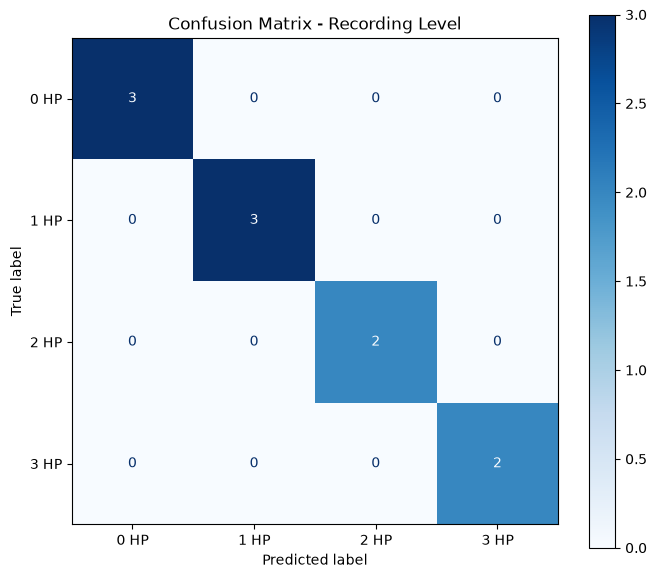

In [9]:

# ==================================================
# CELL 9 - RECORDING-LEVEL EVALUATION
# ==================================================

from sklearn.metrics import confusion_matrix

# Menggabungkan prediksi setiap segmen
recording_predictions = pd.DataFrame({
    "source_file": groups.loc[test_mask].to_numpy(),
    "actual": y_test.to_numpy(),
    "predicted": y_pred_test
})

# Majority voting untuk setiap rekaman
recording_results = (
    recording_predictions
    .groupby("source_file")
    .agg(
        actual=("actual", "first"),
        predicted=(
            "predicted",
            lambda x: x.value_counts().idxmax()
        ),
        total_segments=("predicted", "count")
    )
    .reset_index()
)

# Memeriksa prediksi benar atau salah
recording_results["correct"] = (
    recording_results["actual"]
    == recording_results["predicted"]
)

print("HASIL EVALUASI TINGKAT REKAMAN")
print("=" * 45)

display(
    recording_results.sort_values("source_file")
)

recording_accuracy = accuracy_score(
    recording_results["actual"],
    recording_results["predicted"]
)

recording_f1 = f1_score(
    recording_results["actual"],
    recording_results["predicted"],
    average="macro",
    zero_division=0
)

print(f"Recording Accuracy : {recording_accuracy:.4f}")
print(f"Recording Macro F1 : {recording_f1:.4f}")

# Confusion Matrix tingkat rekaman
fig, ax = plt.subplots(figsize=(7, 6))

ConfusionMatrixDisplay.from_predictions(
    recording_results["actual"],
    recording_results["predicted"],
    labels=[0, 1, 2, 3],
    display_labels=["0 HP", "1 HP", "2 HP", "3 HP"],
    cmap="Blues",
    values_format="d",
    ax=ax
)

ax.set_title("Confusion Matrix - Recording Level")
plt.tight_layout()
plt.show()


In [10]:

# ==================================================
# CELL 10 - STRATIFIED GROUP CROSS-VALIDATION
# ==================================================

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.base import clone

cv = StratifiedGroupKFold(
    n_splits=4,
    shuffle=True,
    random_state=RANDOM_STATE
)

cv_results = []

for fold, (train_idx, val_idx) in enumerate(
    cv.split(X, y, groups),
    start=1
):
    X_cv_train = X.iloc[train_idx]
    X_cv_val = X.iloc[val_idx]

    y_cv_train = y.iloc[train_idx]
    y_cv_val = y.iloc[val_idx]

    train_groups = groups.iloc[train_idx]
    val_groups = groups.iloc[val_idx]

    # Pastikan tidak ada kebocoran antarrekaman
    assert set(train_groups).isdisjoint(
        set(val_groups)
    )

    # Model baru untuk setiap fold
    model_cv = clone(model_rf_harmonic)

    model_cv.fit(X_cv_train, y_cv_train)

    y_cv_pred = model_cv.predict(X_cv_val)

    # Evaluasi tingkat segmen
    segment_accuracy = accuracy_score(
        y_cv_val, y_cv_pred
    )

    segment_f1 = f1_score(
        y_cv_val,
        y_cv_pred,
        average="macro",
        zero_division=0
    )

    # Evaluasi tingkat rekaman
    fold_predictions = pd.DataFrame({
        "source_file": val_groups.to_numpy(),
        "actual": y_cv_val.to_numpy(),
        "predicted": y_cv_pred
    })

    fold_recordings = (
        fold_predictions
        .groupby("source_file")
        .agg(
            actual=("actual", "first"),
            predicted=(
                "predicted",
                lambda x: x.value_counts().idxmax()
            )
        )
        .reset_index()
    )

    recording_accuracy_cv = accuracy_score(
        fold_recordings["actual"],
        fold_recordings["predicted"]
    )

    recording_f1_cv = f1_score(
        fold_recordings["actual"],
        fold_recordings["predicted"],
        average="macro",
        zero_division=0
    )

    cv_results.append({
        "Fold": fold,
        "Train Recordings": train_groups.nunique(),
        "Validation Recordings": val_groups.nunique(),
        "Segment Accuracy": segment_accuracy,
        "Segment Macro F1": segment_f1,
        "Recording Accuracy": recording_accuracy_cv,
        "Recording Macro F1": recording_f1_cv
    })

cv_results_df = pd.DataFrame(cv_results)

print("HASIL GROUP CROSS-VALIDATION")
print("=" * 50)

display(cv_results_df.round(4))

print("\nRATA-RATA CROSS-VALIDATION")
display(
    cv_results_df[
        [
            "Segment Accuracy",
            "Segment Macro F1",
            "Recording Accuracy",
            "Recording Macro F1"
        ]
    ].agg(["mean", "std"]).round(4)
)


HASIL GROUP CROSS-VALIDATION


,Fold,Train Recordings,Validation Recordings,Segment Accuracy,Segment Macro F1,Recording Accuracy,Recording Macro F1
0,1,30,10,0.9700,0.9694,1.0,1.0
1,2,30,10,0.9800,0.9833,1.0,1.0
2,3,30,10,0.9800,0.9774,1.0,1.0
3,4,30,10,0.9579,0.9542,1.0,1.0



RATA-RATA CROSS-VALIDATION


,Segment Accuracy,Segment Macro F1,Recording Accuracy,Recording Macro F1
mean,0.9720,0.9711,1.0,1.0
std,0.0105,0.0126,0.0,0.0


FEATURE IMPORTANCE - RANDOM FOREST


,Feature,Importance
0,harmonic_3_frequency,0.6031
1,fundamental_frequency,0.2301
2,harmonic_2_frequency,0.1404
3,harmonic_2_power,0.0133
4,fundamental_power,0.0121
5,harmonic_3_power,0.0010


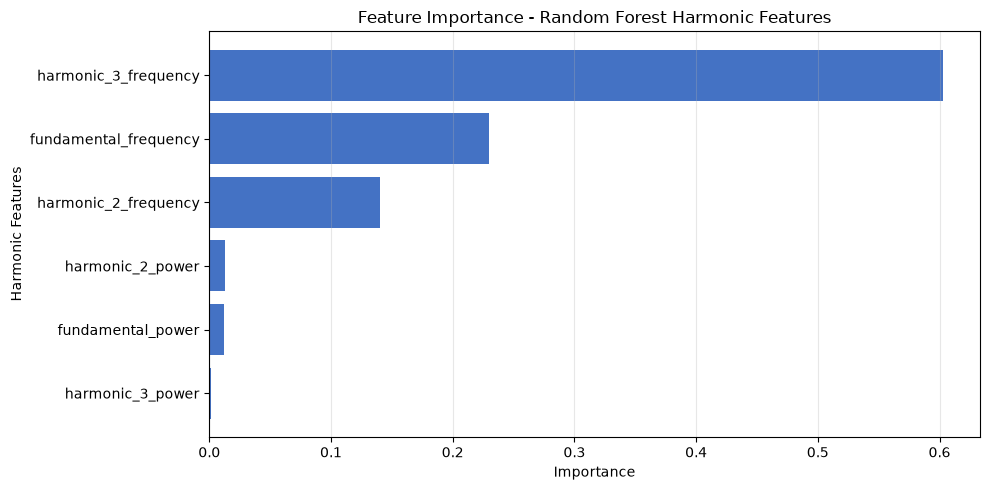

In [11]:

# ==================================================
# CELL 11 - FEATURE IMPORTANCE RANDOM FOREST
# ==================================================

# Mengambil nilai feature importance
feature_importance_df = pd.DataFrame({
    "Feature": harmonic_feature_columns,
    "Importance": model_rf_harmonic.feature_importances_
}).sort_values(
    "Importance",
    ascending=False
).reset_index(drop=True)

print("FEATURE IMPORTANCE - RANDOM FOREST")
print("=" * 45)

display(feature_importance_df.round(4))

# Visualisasi feature importance
fig, ax = plt.subplots(figsize=(10, 5))

ax.barh(
    feature_importance_df["Feature"][::-1],
    feature_importance_df["Importance"][::-1],
    color="#4472C4"
)

ax.set_title(
    "Feature Importance - Random Forest Harmonic Features"
)
ax.set_xlabel("Importance")
ax.set_ylabel("Harmonic Features")
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()


In [12]:

# ==================================================
# CELL 12 - RINGKASAN EVALUASI MODEL
# ==================================================

cv_summary = cv_results_df[
    [
        "Segment Accuracy",
        "Segment Macro F1",
        "Recording Accuracy",
        "Recording Macro F1"
    ]
].mean()

model_summary = pd.DataFrame([
    {
        "Evaluation": "Training",
        "Accuracy": accuracy_score(
            y_train, y_pred_train
        ),
        "Macro F1": f1_score(
            y_train, y_pred_train,
            average="macro",
            zero_division=0
        )
    },
    {
        "Evaluation": "Testing",
        "Accuracy": accuracy_score(
            y_test, y_pred_test
        ),
        "Macro F1": f1_score(
            y_test, y_pred_test,
            average="macro",
            zero_division=0
        )
    },
    {
        "Evaluation": "Cross-Validation (Segment)",
        "Accuracy": cv_summary["Segment Accuracy"],
        "Macro F1": cv_summary["Segment Macro F1"]
    },
    {
        "Evaluation": "Cross-Validation (Recording)",
        "Accuracy": cv_summary["Recording Accuracy"],
        "Macro F1": cv_summary["Recording Macro F1"]
    }
])

print("RINGKASAN EVALUASI MODEL")
display(model_summary.round(4))


RINGKASAN EVALUASI MODEL


,Evaluation,Accuracy,Macro F1
0,Training,0.9661,0.9682
1,Testing,0.9900,0.9875
2,Cross-Validation (Segment),0.9720,0.9711
3,Cross-Validation (Recording),1.0000,1.0000


In [13]:

# ==================================================
# CELL 13 - SIMPAN MODEL DAN HASIL EVALUASI
# ==================================================

# Menyimpan model beserta konfigurasi
model_package = {
    "model": model_rf_harmonic,
    "feature_columns": harmonic_feature_columns,
    "sampling_rate_hz": FS,
    "window_size": WINDOW_SIZE,
    "frequency_bands": FREQUENCY_BANDS,
    "target": "motor_load_hp",
    "classes": [0, 1, 2, 3]
}

model_path = (
    MODEL_DIR / "random_forest_harmonic_motor_load.joblib"
)

joblib.dump(model_package, model_path)

# Menyimpan hasil evaluasi
model_summary.to_csv(
    OUTPUT_DIR / "harmonic_rf_model_summary.csv",
    index=False
)

cv_results_df.to_csv(
    OUTPUT_DIR / "harmonic_rf_cross_validation.csv",
    index=False
)

feature_importance_df.to_csv(
    OUTPUT_DIR / "harmonic_rf_feature_importance.csv",
    index=False
)

recording_results.to_csv(
    OUTPUT_DIR / "harmonic_rf_recording_results.csv",
    index=False
)

print("MODEL DAN HASIL EVALUASI BERHASIL DISIMPAN")
print("=" * 50)
print("Model:", model_path)
print("Jumlah fitur:", len(harmonic_feature_columns))
print("Target:", model_package["target"])


MODEL DAN HASIL EVALUASI BERHASIL DISIMPAN
Model: d:\python\sem 5\Pemrosesan sinyal\Tugas Besar\outputs\models\random_forest_harmonic_motor_load.joblib
Jumlah fitur: 6
Target: motor_load_hp


HASIL ABLATION STUDY


,Feature Set,Mean Accuracy,Std Accuracy,Min Accuracy,Max Accuracy
3,Semua Harmonik,0.9720,0.0091,0.9579,0.9800
2,Harmonik 3,0.9670,0.0088,0.9579,0.9800
1,Harmonik 2,0.6191,0.0861,0.5263,0.7400
0,Fundamental,0.3908,0.0584,0.3000,0.4632


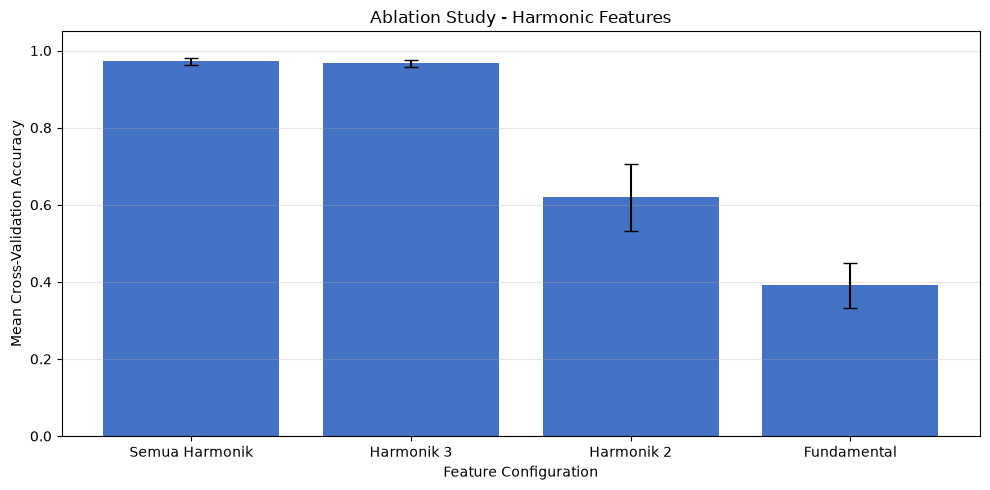

In [14]:

# ==================================================
# CELL 14 - ABLATION STUDY FITUR HARMONIK
# ==================================================

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.base import clone

feature_sets = {
    "Fundamental": [
        "fundamental_frequency",
        "fundamental_power"
    ],
    "Harmonik 2": [
        "harmonic_2_frequency",
        "harmonic_2_power"
    ],
    "Harmonik 3": [
        "harmonic_3_frequency",
        "harmonic_3_power"
    ],
    "Semua Harmonik": harmonic_feature_columns
}

# Menggunakan pembagian CV yang sama untuk setiap konfigurasi
cv = StratifiedGroupKFold(
    n_splits=4,
    shuffle=True,
    random_state=RANDOM_STATE
)

cv_splits = list(cv.split(X, y, groups))

ablation_results = []

for feature_name, selected_features in feature_sets.items():

    X_subset = df_harmonic[selected_features]
    fold_scores = []

    for train_idx, val_idx in cv_splits:

        model = clone(model_rf_harmonic)

        model.fit(
            X_subset.iloc[train_idx],
            y.iloc[train_idx]
        )

        predictions = model.predict(
            X_subset.iloc[val_idx]
        )

        score = accuracy_score(
            y.iloc[val_idx],
            predictions
        )

        fold_scores.append(score)

    ablation_results.append({
        "Feature Set": feature_name,
        "Mean Accuracy": np.mean(fold_scores),
        "Std Accuracy": np.std(fold_scores),
        "Min Accuracy": np.min(fold_scores),
        "Max Accuracy": np.max(fold_scores)
    })

ablation_df = pd.DataFrame(
    ablation_results
).sort_values(
    "Mean Accuracy",
    ascending=False
)

print("HASIL ABLATION STUDY")
display(ablation_df.round(4))

# Visualisasi perbandingan
fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(
    ablation_df["Feature Set"],
    ablation_df["Mean Accuracy"],
    yerr=ablation_df["Std Accuracy"],
    capsize=5,
    color="#4472C4"
)

ax.set_title("Ablation Study - Harmonic Features")
ax.set_ylabel("Mean Cross-Validation Accuracy")
ax.set_xlabel("Feature Configuration")
ax.set_ylim(0, 1.05)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


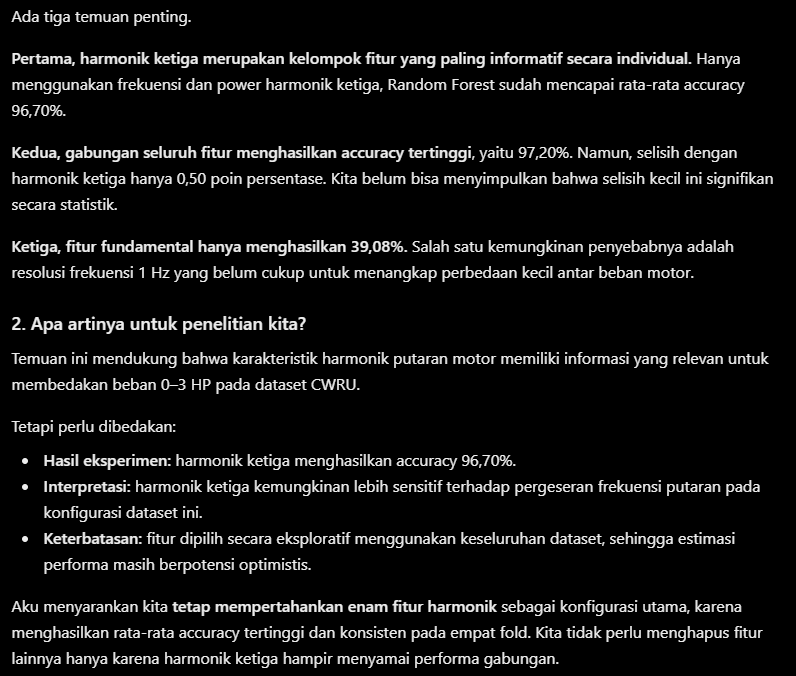

In [15]:

# ==================================================
# CELL 15 - DATA INTEGRITY & LEAKAGE CHECK
# ==================================================

# 1. Setiap rekaman hanya memiliki satu label
label_counts = (
    df_harmonic
    .groupby("source_file")["motor_load_hp"]
    .nunique()
)

assert (label_counts == 1).all()

# 2. Tidak ada rekaman yang muncul di training dan testing
train_recordings = set(groups.loc[train_mask])
test_recordings = set(groups.loc[test_mask])

assert train_recordings.isdisjoint(test_recordings)

# 3. Tidak ada nilai NaN atau infinite pada fitur
assert np.isfinite(
    df_harmonic[harmonic_feature_columns].to_numpy()
).all()

# 4. Periksa duplikasi identitas segmen
duplicate_segments = df_harmonic.duplicated(
    subset=["source_file", "segment_id"]
).sum()

assert duplicate_segments == 0

# 5. Semua kelas tersedia pada training dan testing
assert set(y_train.unique()) == {0, 1, 2, 3}
assert set(y_test.unique()) == {0, 1, 2, 3}

print("DATA INTEGRITY CHECK")
print("=" * 40)
print("Jumlah rekaman:", groups.nunique())
print("Jumlah segmen:", len(df_harmonic))
print("Duplikasi identitas segmen:", duplicate_segments)
print("Overlap rekaman train-test:", len(
    train_recordings.intersection(test_recordings)
))
print("\nSeluruh pemeriksaan teknis berhasil!")


DATA INTEGRITY CHECK
Jumlah rekaman: 40
Jumlah segmen: 395
Duplikasi identitas segmen: 0
Overlap rekaman train-test: 0

Seluruh pemeriksaan teknis berhasil!


In [16]:

# ==================================================
# CELL 16 - SIMPAN HASIL ABLATION STUDY
# ==================================================

ablation_path = (
    OUTPUT_DIR / "harmonic_rf_ablation_study.csv"
)

ablation_df.to_csv(
    ablation_path,
    index=False
)

print("HASIL ABLATION STUDY BERHASIL DISIMPAN")
print("=" * 45)
print("Lokasi:", ablation_path)

display(ablation_df.round(4))


HASIL ABLATION STUDY BERHASIL DISIMPAN
Lokasi: d:\python\sem 5\Pemrosesan sinyal\Tugas Besar\outputs\harmonic_rf_ablation_study.csv


,Feature Set,Mean Accuracy,Std Accuracy,Min Accuracy,Max Accuracy
3,Semua Harmonik,0.9720,0.0091,0.9579,0.9800
2,Harmonik 3,0.9670,0.0088,0.9579,0.9800
1,Harmonik 2,0.6191,0.0861,0.5263,0.7400
0,Fundamental,0.3908,0.0584,0.3000,0.4632


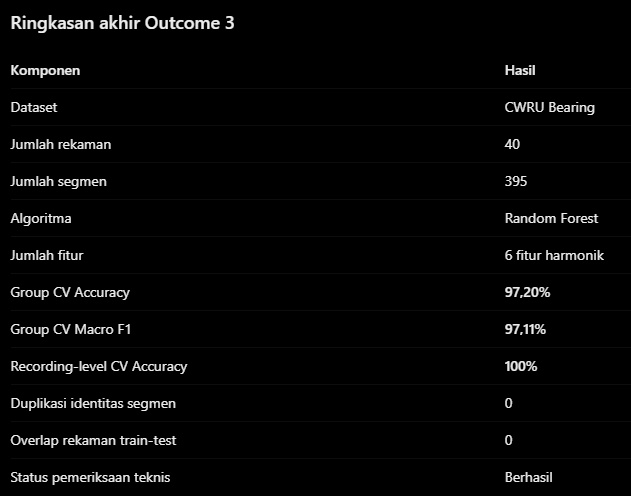